In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

X_test_enc = pd.read_csv('../data/X_test_enc.csv')
y_test = pd.read_csv('../data/y_test.csv').squeeze()

xgb_calibrated = joblib.load('../src/xgb_calibrated_model.pkl')

# Calibrated probabilities: the cost sweep only makes sense if probabilities are trustworthy
probs = xgb_calibrated.predict_proba(X_test_enc)[:, 1]
print(probs[:10])

[0.32132276 0.09589491 0.67927417 0.4761461  0.25298303 0.21724868
 0.26539683 0.28380139 0.43059053 0.16671329]


In [2]:
avg_credit_amount = pd.read_csv('../data/german_credit_clean.csv')['credit_amount'].mean()
print("Average credit amount:", avg_credit_amount)

# Illustrative assumption: a missed defaulter costs the average exposure,
# a wrongly rejected good applicant costs ~10% of it (lost margin)
COST_FN = avg_credit_amount
COST_FP = avg_credit_amount * 0.10

print(f"Cost per False Negative: {COST_FN:.2f} DM")
print(f"Cost per False Positive: {COST_FP:.2f} DM")
print(f"Cost ratio (FN:FP): {COST_FN / COST_FP:.1f}:1")

Average credit amount: 3271.258
Cost per False Negative: 3271.26 DM
Cost per False Positive: 327.13 DM
Cost ratio (FN:FP): 10.0:1


In [3]:
thresholds = np.arange(0.01, 1.0, 0.01)
results = []

for t in thresholds:
    preds = (probs >= t).astype(int)
    fn = ((preds == 0) & (y_test == 1)).sum()
    fp = ((preds == 1) & (y_test == 0)).sum()
    tp = ((preds == 1) & (y_test == 1)).sum()
    tn = ((preds == 0) & (y_test == 0)).sum()
    results.append({'threshold': t, 'fn': fn, 'fp': fp, 'tp': tp, 'tn': tn,
                    'total_cost': fn * COST_FN + fp * COST_FP})

cost_df = pd.DataFrame(results)
best_row = cost_df.loc[cost_df['total_cost'].idxmin()]
print(best_row)

threshold         0.0300
fn                0.0000
fp              121.0000
tp               60.0000
tn               19.0000
total_cost    39582.2218
Name: 2, dtype: float64


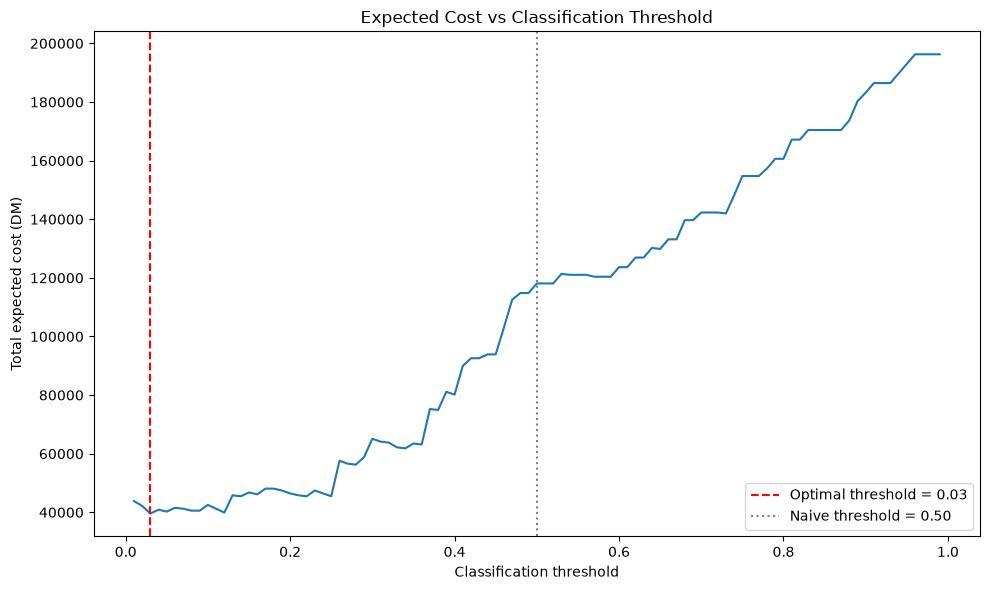

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(cost_df['threshold'], cost_df['total_cost'])
plt.axvline(best_row['threshold'], color='red', linestyle='--',
            label=f"Optimal threshold = {best_row['threshold']:.2f}")
plt.axvline(0.5, color='gray', linestyle=':', label='Naive threshold = 0.50')
plt.xlabel('Classification threshold')
plt.ylabel('Total expected cost (DM)')
plt.title('Expected Cost vs Classification Threshold')
plt.legend()
plt.tight_layout()
plt.savefig('../reports/figures/cost_vs_threshold.png', dpi=100)
plt.show()

In [5]:
candidate_thresholds = {
    'Naive (0.50)': 0.50,
    'Pure cost-minimum (0.03)': 0.03,
    'Moderate (0.20)': 0.20,
    'Moderate (0.35)': 0.35,
}

comparison = []
for name, t in candidate_thresholds.items():
    row = cost_df[np.isclose(cost_df['threshold'], t, atol=0.005)].iloc[0]
    preds = (probs >= t).astype(int)
    comparison.append({
        'strategy': name,
        'threshold': t,
        'fn': row['fn'],
        'fp': row['fp'],
        'total_cost': row['total_cost'],
        'approval_rate': (row['tn'] + row['fn']) / len(y_test),
        'precision': precision_score(y_test, preds, zero_division=0),
        'recall': recall_score(y_test, preds, zero_division=0),
    })

comparison_df = pd.DataFrame(comparison)
comparison_df

,strategy,threshold,fn,fp,total_cost,approval_rate,precision,recall
0,Naive (0.50),0.50,35.0,11.0,118092.4138,0.820,0.694444,0.416667
1,Pure cost-minimum (0.03),0.03,0.0,121.0,39582.2218,0.095,0.331492,1.000000
2,Moderate (0.20),0.20,7.0,72.0,46451.8636,0.375,0.424000,0.883333
3,Moderate (0.35),0.35,16.0,34.0,63462.4052,0.610,0.564103,0.733333


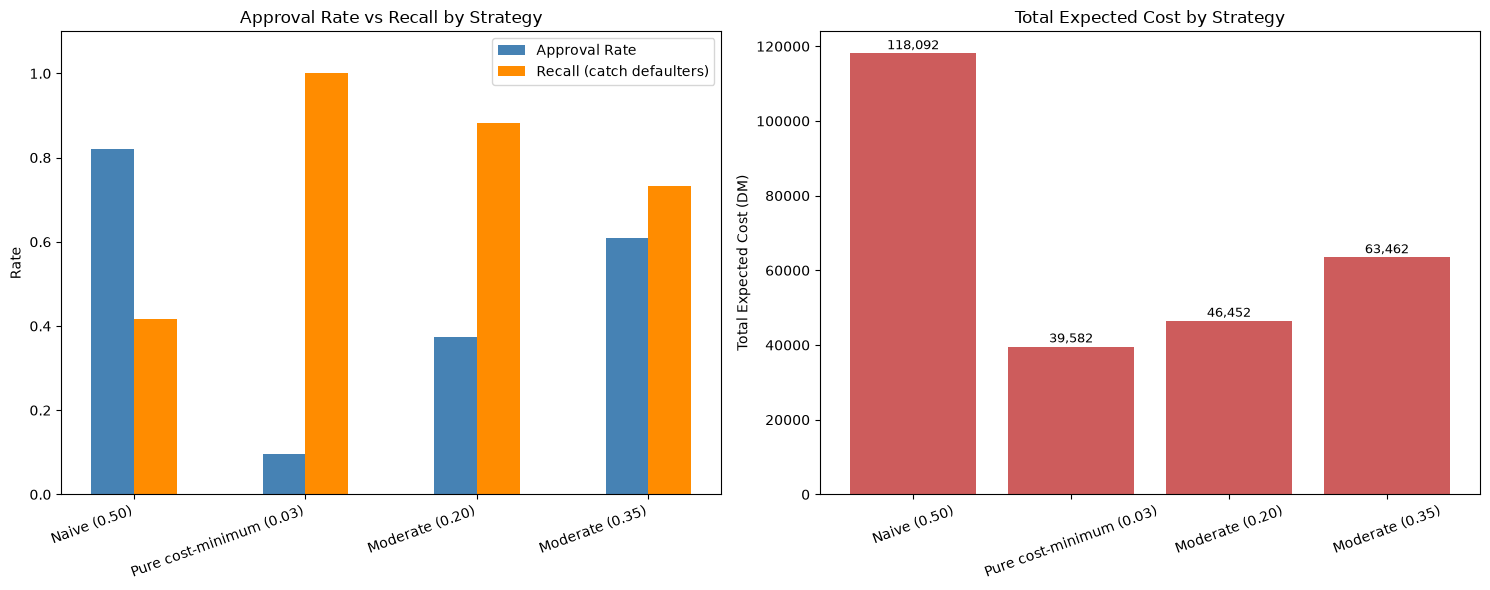

In [6]:
strategies = comparison_df['strategy'].tolist()
x = np.arange(len(strategies))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(x - width / 2, comparison_df['approval_rate'], width, label='Approval Rate', color='steelblue')
axes[0].bar(x + width / 2, comparison_df['recall'], width, label='Recall (catch defaulters)', color='darkorange')
axes[0].set_xticks(x)
axes[0].set_xticklabels(strategies, rotation=20, ha='right')
axes[0].set_ylabel('Rate')
axes[0].set_title('Approval Rate vs Recall by Strategy')
axes[0].legend()
axes[0].set_ylim(0, 1.1)

bars = axes[1].bar(strategies, comparison_df['total_cost'], color='indianred')
axes[1].set_ylabel('Total Expected Cost (DM)')
axes[1].set_title('Total Expected Cost by Strategy')
axes[1].tick_params(axis='x', rotation=20)
for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f'{h:,.0f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/threshold_strategy_comparison.png', dpi=100)
plt.show()

In [7]:
RECOMMENDED_THRESHOLD = 0.20
final_preds = (probs >= RECOMMENDED_THRESHOLD).astype(int)

with open('../src/recommended_threshold.json', 'w') as f:
    json.dump({
        'threshold': RECOMMENDED_THRESHOLD,
        'rationale': 'Cost-aware moderate threshold balancing approval volume against default risk, given 10:1 FN:FP cost ratio'
    }, f)

pd.DataFrame({'y_true': y_test.values, 'prob': probs, 'pred': final_preds}).to_csv(
    '../data/test_predictions_final.csv', index=False)

print("Rejected at 0.20:", final_preds.sum(), "of", len(final_preds))

Rejected at 0.20: 125 of 200
